# Session 5 — the 33 features for a benign and a malignant lesion

*Homework during class.* Part 1 replays the toy lesion from class so each feature has a number we can check by hand.
Part 2 computes the same **33 features** for one real **benign** and one real **malignant** MILK10k lesion and reads what differs.

| group | features | count |
|---|---|---|
| colour statistics | mean and std of R, G, B | 6 |
| colour histogram | 8 bins × 3 channels, normalised to sum to 1 per channel | 24 |
| texture | edge density (mean Sobel magnitude), roughness (mean local variance), sharpness (variance of the Laplacian) | 3 |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

from milk10k import features as F
from milk10k.data import IMAGE_DIR, PROJECT_ROOT

np.set_printoptions(precision=2, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

lesions = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "lesions.csv")

## 1. The toy lesion from class

In [2]:
toy = np.array([
    [100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
    [100, 100,  10,  10,  10],
], dtype=float)                         # 100 = skin, 10 = lesion
toy

array([[100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.],
       [100., 100.,  10.,  10.,  10.]])

In [3]:
# 1a. Histogram: how many pixels fall in each intensity bin
counts, edges = np.histogram(toy, bins=4, range=(0, 256))
print("counts      ", counts)
print("proportions ", counts / toy.size)

# 1b. Mean and std (std two ways: np.std, and sqrt(mean(x^2) - mean(x)^2))
print("mean", toy.mean())
print("std ", toy.std(), "=", np.sqrt((toy**2).mean() - toy.mean()**2))

counts       [ 9 16  0  0]
proportions  [0.36 0.64 0.   0.  ]
mean 67.6
std  43.2 = 43.20000000000001


[[ 10.  10. 100.  10. 100.]
 [ 10. 100.  10. 100. 100.]
 [ 10. 100. 100. 100. 100.]
 [100. 100. 100.  10. 100.]
 [100. 100. 100.  10.  10.]]
histogram [ 9 16  0  0]  mean 67.6  std 43.2


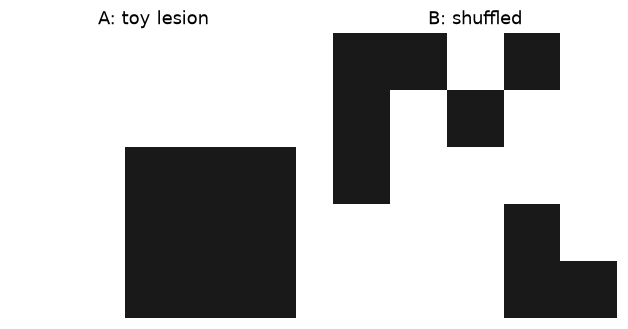

In [4]:
# 1c. The same pixels in a random order: histogram, mean and std cannot tell them apart
rng = np.random.default_rng(3)
shuffled = rng.permutation(toy.ravel()).reshape(5, 5)
print(shuffled)
print("histogram", np.histogram(shuffled, bins=4, range=(0, 256))[0],
      " mean", shuffled.mean(), " std", round(shuffled.std(), 1))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(toy, cmap="gray", vmin=0, vmax=100);      axes[0].set_title("A: toy lesion")
axes[1].imshow(shuffled, cmap="gray", vmin=0, vmax=100); axes[1].set_title("B: shuffled")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

Both images hold nine dark and sixteen bright pixels, so the 12 colour-statistics and histogram numbers are identical. What
differs is **where** the pixels sit, and that is what the texture features measure. The simplest version counts how often a
pixel differs from its right neighbour (`img[:, 1:]` against `img[:, :-1]`).

In [5]:
# 1d. Texture, simplest form: left -> right changes between neighbours
def n_changes(img):
    return (img[:, 1:] != img[:, :-1]).sum()

print("toy lesion:", n_changes(toy), "  shuffled:", n_changes(shuffled))

# 1e. Edge density: mean Sobel magnitude (Session 4) over the 3x3 interior
gx = ndimage.sobel(toy, axis=1)
gy = ndimage.sobel(toy, axis=0)
magnitude = np.hypot(gx, gy)
print(magnitude[1:-1, 1:-1])
print("edge density (interior):", round(magnitude[1:-1, 1:-1].mean(), 1))

toy lesion: 3   shuffled: 10
[[127.28 284.6  360.  ]
 [284.6  381.84 360.  ]
 [360.   360.     0.  ]]
edge density (interior): 279.8


One compact blob gives few changes and a shuffled image gives many, while histogram, mean and std stay the same. That is
why the 33 features include texture numbers next to the colour ones. The repo's `texture_features` does the same on the
simple-average grayscale, with a 9×9 local variance for roughness and the Laplacian variance for sharpness:

In [6]:
import inspect
print(inspect.getsource(F.texture_features))
toy_rgb = np.stack([toy] * 3, axis=2)
print("toy lesion  [edge_density, roughness, laplacian_var]:", F.texture_features(toy_rgb))
print("shuffled    [edge_density, roughness, laplacian_var]:", F.texture_features(np.stack([shuffled] * 3, axis=2)))

def texture_features(rgb: np.ndarray) -> np.ndarray:
    """Edge density (mean Sobel magnitude), roughness (mean 9x9 local variance),
    sharpness (variance of the Laplacian), all on the simple-average grayscale."""
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    return np.array([np.hypot(gx, gy).mean(),
                     (local_sq_mean - local_mean**2).mean(),
                     ndimage.laplace(gray).var()])

toy lesion  [edge_density, roughness, laplacian_var]: [ 158.33 1848.89 4536.  ]
shuffled    [edge_density, roughness, laplacian_var]: [  210.23  1859.95 25272.  ]


Same nine and sixteen pixels, yet the Laplacian variance (sharpness) is 5.6 times higher when they are scattered (25,272
against 4,536) and edge density is higher too (210 against 158). Roughness barely moves here (1,849 against 1,860) because a
9×9 window on a 5×5 image averages everything; on the 200×150 photographs it is a genuine local measure.

## 2. A real benign and a real malignant lesion

Both are dermoscopic images from MILK10k: a melanocytic **nevus** (`diagnosis_1` = Benign) and a **melanoma** (`diagnosis_1`
= Malignant). They are the same two images as in the Session 2 notebook, so the pixels are already familiar. Features are
computed the way the baseline computes them: image resized to 200×150, then the three groups below.

In [7]:
CASES = {"Benign": "ISIC_2348795", "Malignant": "ISIC_6511897"}      # NV and MEL
meta = lesions.set_index("derm_id").loc[list(CASES.values()), ["diagnosis_1", "dx", "age", "sex"]]
meta.insert(0, "case", list(CASES))
meta

,case,diagnosis_1,dx,age,sex
derm_id,,,,,
ISIC_2348795,Benign,Benign,NV,85.0,male
ISIC_6511897,Malignant,Malignant,MEL,70.0,male


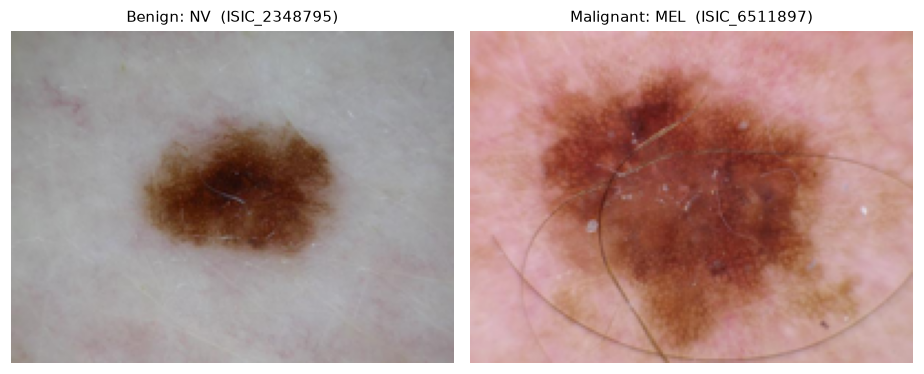

{'Benign': (150, 200, 3), 'Malignant': (150, 200, 3)}


In [8]:
imgs = {k: F.load_rgb(IMAGE_DIR / f"{i}.jpg") for k, i in CASES.items()}      # float (150, 200, 3)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, (k, rgb) in zip(axes, imgs.items()):
    ax.imshow(rgb.astype(np.uint8)); ax.axis("off")
    ax.set_title(f"{k}: {meta.loc[CASES[k], 'dx']}  ({CASES[k]})", fontsize=10)
plt.tight_layout(); plt.show()
print({k: v.shape for k, v in imgs.items()})

### The 33 features

In [9]:
GROUPS = ["color_stats", "color_hist", "texture"]                     # the 33; HSV is Session 5's extra
names = [n for g in GROUPS for n in F.FEATURE_GROUPS[g]]
group_of = [g for g in GROUPS for _ in F.FEATURE_GROUPS[g]]

def thirty_three(rgb):
    return np.concatenate([F.color_stats(rgb), F.color_histogram(rgb), F.texture_features(rgb)])

table = pd.DataFrame({k: thirty_three(v) for k, v in imgs.items()}, index=names)
table.insert(0, "group", group_of)
table["Malignant - Benign"] = table["Malignant"] - table["Benign"]
print(len(names), "features:", {g: group_of.count(g) for g in GROUPS})
table.round(3)

33 features: {'color_stats': 6, 'color_hist': 24, 'texture': 3}


,group,Benign,Malignant,Malignant - Benign
mean_R,color_stats,153.653,183.636,29.984
mean_G,color_stats,145.863,128.046,-17.817
mean_B,color_stats,144.446,119.378,-25.068
std_R,color_stats,23.568,32.203,8.635
std_G,color_stats,35.113,42.404,7.291
std_B,color_stats,41.528,48.763,7.235
hist_R0,color_hist,0.000,0.000,0.000
hist_R1,color_hist,0.012,0.000,-0.012
hist_R2,color_hist,0.043,0.002,-0.042
hist_R3,color_hist,0.050,0.078,0.027


Histogram bin *k* holds the share of pixels with intensity in [32·k, 32·(k+1)); bin 0 is the darkest, bin 7 the brightest.
Each channel's 8 bins sum to 1.

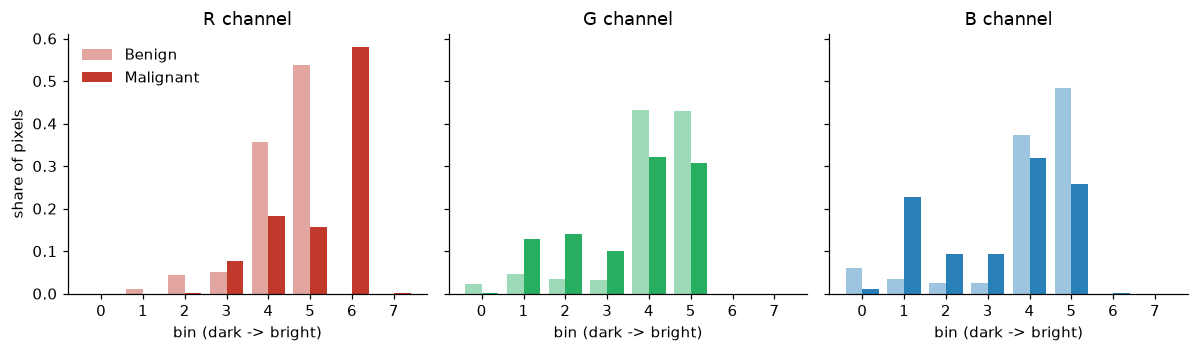

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
x = np.arange(8); w = 0.4
for ax, ch, col in zip(axes, "RGB", ["#c0392b", "#27ae60", "#2980b9"]):
    for j, (k, shade) in enumerate([("Benign", 0.45), ("Malignant", 1.0)]):
        vals = table.loc[[f"hist_{ch}{b}" for b in range(8)], k].to_numpy()
        ax.bar(x + (j - 0.5) * w, vals, w, color=col, alpha=shade, label=k)
    ax.set_title(f"{ch} channel"); ax.set_xlabel("bin (dark -> bright)"); ax.set_xticks(x)
axes[0].set_ylabel("share of pixels"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

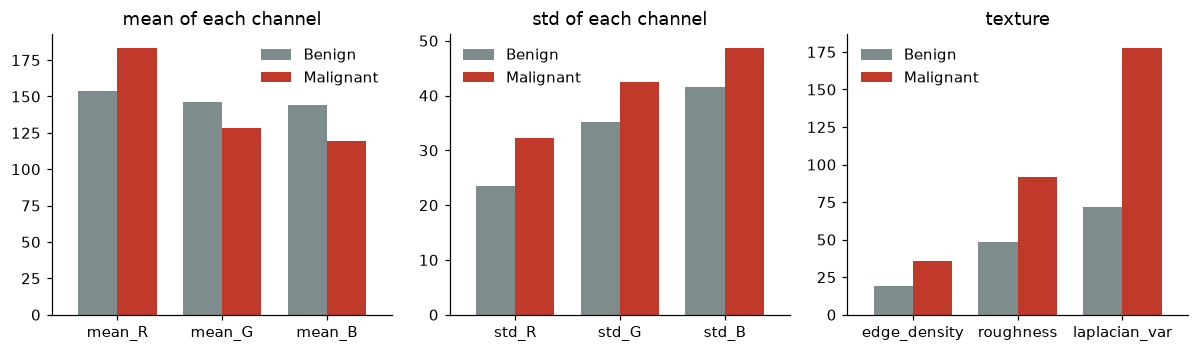

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (title, rows) in zip(axes, [("mean of each channel", ["mean_R", "mean_G", "mean_B"]),
                                    ("std of each channel", ["std_R", "std_G", "std_B"]),
                                    ("texture", ["edge_density", "roughness", "laplacian_var"])]):
    t = table.loc[rows, ["Benign", "Malignant"]]
    t.plot.bar(ax=ax, color=["#7f8c8d", "#c0392b"], rot=0, width=0.75)
    ax.set_title(title); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading the two columns.**

- **Colour.** The melanoma is redder and darker in the other channels: mean R 183.6 against 153.7 (+30), while mean G falls by
  17.8 and mean B by 25.1. The gap between red and blue is 64 for the melanoma and 9 for the nevus. The histograms show it:
  58% of the melanoma's red pixels sit in bin 6 (192 to 223) while none of the nevus's do (54% of the nevus sit in bin 5), and
  23% of its blue pixels sit in bin 1 (32 to 63) against 3.5% for the nevus, which is the dark lesion body.
- **Spread.** All three standard deviations are 7 to 9 higher for the melanoma, i.e. more contrast between lesion and skin.
- **Texture.** All three texture features are larger for the melanoma: edge density 35.5 against 19.2 (1.8×), roughness 91.9
  against 48.5 (1.9×) and Laplacian variance 177.9 against 71.6 (2.5×). Its surface changes more from pixel to pixel,
  which fits an irregular border and mixed pigmentation.

### Is the difference typical, or just these two lesions?

In [12]:
# Mean of the same features over every lesion's dermoscopic image, by diagnosis_1 (cached by the baseline).
feats = F.feature_table(lesions["derm_id"], cache=F.FEATURE_DIR / "features.npz")[names]
by_class = feats.groupby(lesions.set_index("derm_id")["diagnosis_1"]).mean().T
print(lesions["diagnosis_1"].value_counts().to_dict())
pick = ["mean_R", "mean_G", "mean_B", "std_R", "std_G", "std_B", "edge_density", "roughness", "laplacian_var"]
by_class.loc[pick].round(2)

{'Malignant': 3634, 'Benign': 1483, 'Indeterminate': 123}


diagnosis_1,Benign,Indeterminate,Malignant
mean_R,168.70,166.86,171.71
mean_G,141.47,128.40,138.10
mean_B,140.73,129.23,135.62
std_R,23.20,19.72,18.82
std_G,30.30,24.38,23.12
std_B,34.80,27.41,25.59
edge_density,28.44,40.20,28.94
roughness,78.04,117.06,74.55
laplacian_var,176.07,287.81,165.61


**No.** Over all lesions the two classes look almost the same on these numbers: mean R 168.7 (Benign) against 171.7
(Malignant), edge density 28.4 against 28.9, roughness 78.0 against 74.6. Some differences even flip sign: the standard
deviations of G and B are larger for Benign on average (std B 34.8 against 25.6) but were larger for our melanoma. The big gaps
in the table above therefore belong to these two images (one nevus is pale and smooth, one melanoma is dark and rough), not to
the classes. Class-level signal is much weaker and is spread over many features at once, which is why Session 5's baseline
combines all 33 (plus clinical data) in a model instead of thresholding one number, and why its test macro-F1 is 0.53
rather than near 1.